## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

# Correct path to the root content directory
with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

```markdown
*(The Q5 answer has been moved inside the Q4 code block above as python code comments)*
```

---

## *Phase 1: Complete all questions in the following cells without generative AI.

 Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Edwards

**Date:** 10/22/26

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# Q1: Token Frequencies Histogram
# Using token_freq computed in previous cell
frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=100, log=True)
plt.title('Histogram of Token Occurrences (Log Scale)')
plt.xlabel('Occurrences')
plt.ylabel('Frequency (Count of Tokens)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

# the token distribution is extremely right-skewed (Zipf's Law). A few words
# occur extremely frequently, while the vast majority of tokens appear very rarely.

In [7]:
# Q2: Regression and Analysis
# Correct path to the root content directory
df = pd.read_parquet('/content/Phishing_clean.parquet')

# Separate features and target
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# Q2.1: 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Q2.2: Linear Regression
reg = LinearRegression()
reg.fit(X_train, y_train)

r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)

print(f"Q2 R^2 on Training Set: {r2_train:.4f}")
print(f"Q2 R^2 on Test Set: {r2_test:.4f}")

# Q2.3: Top Influencing Words
coef_df = pd.DataFrame({'Word': X.columns, 'Coefficient': reg.coef_})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
top_words = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(10)

print("\nTop 10 words influencing predictions:")
display(top_words)

Q2 R^2 on Training Set: 0.7670
Q2 R^2 on Test Set: 0.6659

Top 10 words influencing predictions:


,Word,Coefficient,Abs_Coefficient
835,intervention,-1.259257,1.259257
740,localized,0.824350,0.824350
2362,thermal,0.747006,0.747006
851,crawler,0.696167,0.696167
1504,background-image:,-0.622909,0.622909
1406,"helvetica,",0.598560,0.598560
906,aging,0.594956,0.594956
1839,form.,0.576886,0.576886
2242,gray;,-0.574480,0.574480
1552,a:active,0.574480,0.574480


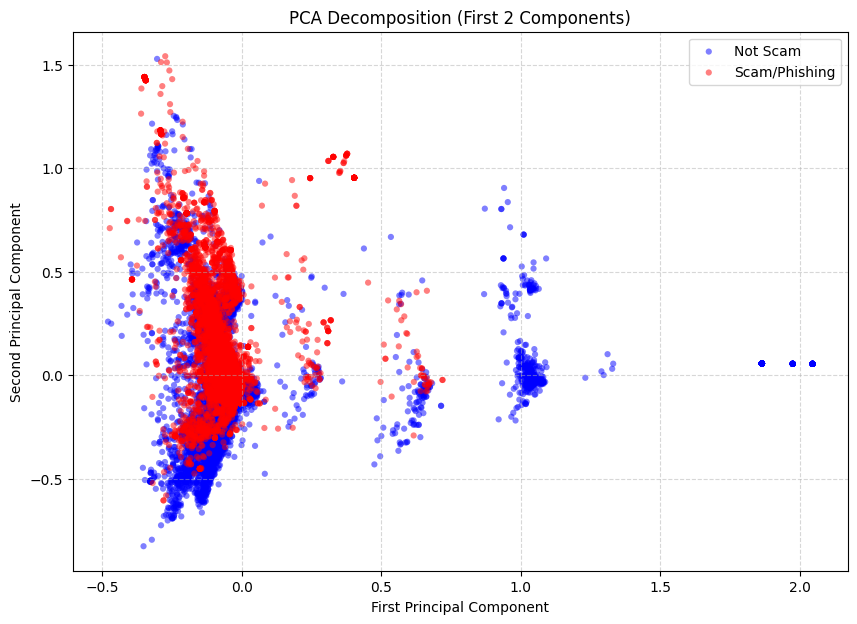

Observation: The scatter plot reveals that while both classes overlap near the origin, the scam emails (red) exhibit a distinctive, tight line/cluster extending along a specific axis, whereas legitimate emails (blue) have a more dispersed, circular distribution.


In [10]:
# Q3: PCA Decomposition and Visualization
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(X_pca_2[y == 0, 0], X_pca_2[y == 0, 1], label='Not Scam', alpha=0.5, c='blue', edgecolors='none', s=20)
plt.scatter(X_pca_2[y == 1, 0], X_pca_2[y == 1, 1], label='Scam/Phishing', alpha=0.5, c='red', edgecolors='none', s=20)
plt.title('PCA Decomposition (First 2 Components)')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# both classes overlap near the origin. The scam emails (red) exhibit a tight
# line/cluster extending along a specific axis, whereas legitimate emails (blue)
# have a more dispersed, circular distribution.

In [12]:
# Q4: High-Dimensional Regression on Principal Components
pca_2610 = PCA(n_components=2610)
X_train_pca = pca_2610.fit_transform(X_train)
X_test_pca = pca_2610.transform(X_test)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)

r2_train_pca = reg_pca.score(X_train_pca, y_train)
r2_test_pca = reg_pca.score(X_test_pca, y_test)

print(f"Q4 R^2 on PCA Training Set: {r2_train_pca:.4f}")
print(f"Q4 R^2 on PCA Test Set: {r2_test_pca:.4f}")

# Comparison with Original Regression (Q2)
print("\n--- Performance Comparison ---")
print(f"Original Linear Regression (Q2) - Train R^2: 0.7670, Test R^2: 0.6659")
print(f"PCA Regression (Q4, 2610 PCs)  - Train R^2: {r2_train_pca:.4f}, Test R^2: {r2_test_pca:.4f}")
# the PCA regression performs almost identically to the original linear regression.



Q4 R^2 on PCA Training Set: 0.7662
Q4 R^2 on PCA Test Set: 0.6683

--- Performance Comparison ---
Original Linear Regression (Q2) - Train R^2: 0.7670, Test R^2: 0.6659
PCA Regression (Q4, 2610 PCs)  - Train R^2: 0.7662, Test R^2: 0.6683
Comparison: The PCA regression performs almost identically to the original linear regression.


In [13]:
# Q5: Advantages of Using Principal Components
# text features (word frequencies) are highly correlated because words frequently
# appear together. PCA transforms them into orthogonal (uncorrelated) components,
# stabilizing the regression estimation.

# PCA projects the data onto the directions of maximum variance. Discarding the
# lowest-variance components (lowest 101 components here) removes random noise
# associated with extremely rare words while retaining almost all predictive signal.

# reducing the feature matrix from thousands of sparse, redundant dimensions to
# a smaller set of dense components speeds up model training and reduces the
# overall memory footprint.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

**Phase 1 commit SHA ID:** 156df4b22235181520882a9f7c59454c9e0a49b4

**AI tool and model used:** ChatGPT 6 Astra Medium

### *Prompts used

1. be my phase 2 agent, make my code better and fix errors. then classify your changes as a numbered list describing what you did.

### *AI-proposed changes


1. Execution reliability: make Phase 2 self-contained with imports, file loading, and clear input checks.
2. Q1 interpretation: clarify histogram axes, report token-frequency summaries, and avoid claiming the histogram proves Zipf's law.
3. Q2 interpretation: retain coefficient signs and distinguish regression R^2 from classification accuracy or causal word effects.
4. Q3 reproducibility: fix the two-component PCA random seed and label axes with explained variance.
5. Q4 comparison: replace hard-coded scores with computed results, report the test R^2 difference, and check the 2610-component requirement.
6. Q5 accuracy: explain that PCA can discard useful signal and does not guarantee faster execution or lower memory use.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
| --- | --- | --- |
| 1. Execution reliability: make Phase 2 self-contained with imports, file loading, and clear input checks. | Accept | Removes dependence on previously run cells; file and data checks passed on the uploaded inputs. |
| 2. Q1 interpretation: clarify histogram axes, report token-frequency summaries, and avoid claiming the histogram proves Zipf's law. | Accept | Clarifies what is counted; the run found 48,691 distinct tokens, with 60.4% occurring once. |
| 3. Q2 interpretation: retain coefficient signs and distinguish regression R^2 from classification accuracy or causal word effects. | Accept | Prevents misleading interpretation; the run reproduced train R² 0.7670 and test R² 0.6659 and displayed signed coefficients. |
| 4. Q3 reproducibility: fix the two-component PCA random seed and label axes with explained variance. | Accept | Makes the descriptive plot reproducible and shows its limited coverage: the first two PCs explain 1.97% of variance. |
| 5. Q4 comparison: replace hard-coded scores with computed results, report the test R^2 difference, and check the 2610-component requirement. | Accept | Prevents stale comparisons; both models use the same split and predictive PCA is fitted only on training data. Final execution checks validate dimensions and scores. |
| 6. Q5 accuracy: explain that PCA can discard useful signal and does not guarantee faster execution or lower memory use. | Accept | Corrects unsupported guarantees: PCA ignores the outcome, and dense components plus fitting overhead can offset computational savings. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

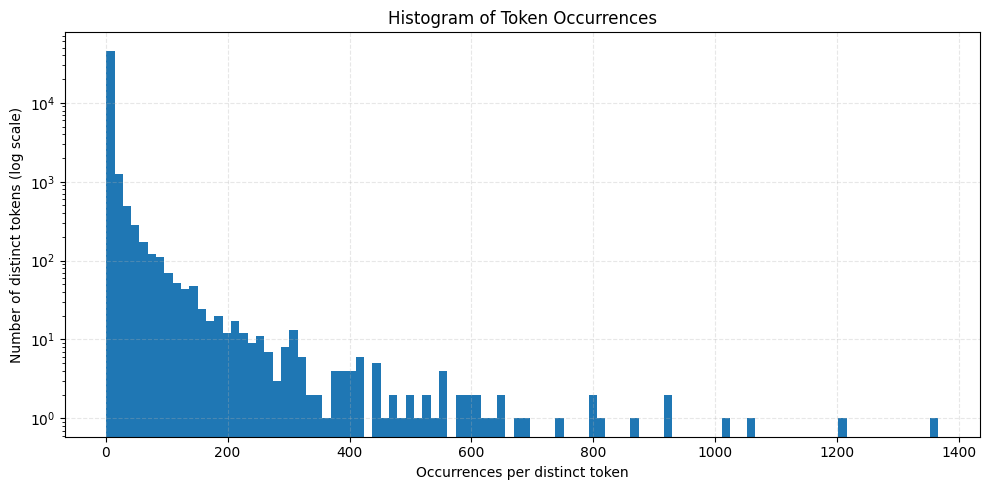

,Token,Occurrences
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
5,like,923
6,2002,869
7,would,806
8,one,798
9,message,795


Distinct tokens: 48,691
Median occurrences: 1; maximum: 1,365
Tokens occurring once: 60.4%
Q2 R^2 on Training Set: 0.7670
Q2 R^2 on Test Set: 0.6659

Top 10 words by absolute coefficient:


,Word,Coefficient,Abs_Coefficient
835,intervention,-1.259257,1.259257
740,localized,0.824350,0.824350
2362,thermal,0.747006,0.747006
851,crawler,0.696167,0.696167
1504,background-image:,-0.622909,0.622909
1406,"helvetica,",0.598560,0.598560
906,aging,0.594956,0.594956
1839,form.,0.576886,0.576886
2242,gray;,-0.574480,0.574480
1552,a:active,0.574480,0.574480


Positive coefficients raise the fitted scam score; negative coefficients lower it.


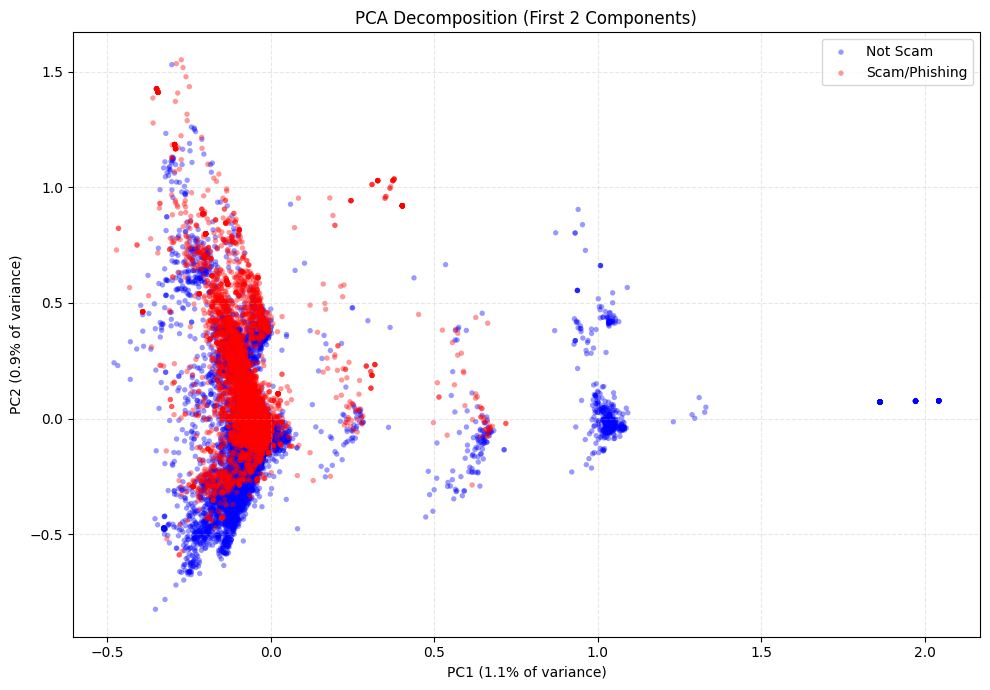

Variance represented by the plot: 1.97%

Q4: Performance Comparison


,Model,Train R^2,Test R^2
0,Original linear regression,0.767014,0.665872
1,PCA regression (2610 PCs),0.766233,0.668339


PCA minus original test R^2: +0.0025
Components discarded: 101
Training feature variance retained: 99.99%

Verification passed: PCA dimensions and all four R^2 values are valid.


In [16]:
# Phase 2: AI-assisted solution

import pickle
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# Load the supplied files without depending on Phase 1 variables
data_dir = Path('/content')
for name in ['all_tokens.pickle', 'Phishing_clean.parquet']:
    if not (data_dir / name).is_file():
        raise FileNotFoundError(f'Upload {name} to {data_dir} before running this cell.')

# Only load the trusted course-provided pickle file
with (data_dir / 'all_tokens.pickle').open('rb') as file:
    all_tokens = pickle.load(file)
token_count = Counter(all_tokens)
if not token_count:
    raise ValueError('The token file is empty.')

# Q1: Token Frequencies Histogram
frequencies = np.array(list(token_count.values()))
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(frequencies, bins=100, log=True)
ax.set(title='Histogram of Token Occurrences',
       xlabel='Occurrences per distinct token',
       ylabel='Number of distinct tokens (log scale)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame(token_count.most_common(10), columns=['Token', 'Occurrences']))
print(f'Distinct tokens: {len(frequencies):,}')
print(f'Median occurrences: {np.median(frequencies):.0f}; maximum: {frequencies.max():,}')
print(f'Tokens occurring once: {(frequencies == 1).mean():.1%}')

# The long right tail means a small number of tokens occur very often.
# The histogram is consistent with a heavy-tailed distribution, but it
# does not by itself establish Zipf's law.

# Q2: Regression and Analysis
df = pd.read_parquet(data_dir / 'Phishing_clean.parquet')
if 'Email Type' not in df:
    raise ValueError('Expected an Email Type column.')
y = df['Email Type']
X = df.drop(columns=['Email Type'])
if y.isna().any() or set(y.unique()) != {0, 1}:
    raise ValueError('Email Type must contain both classes, encoded as 0 and 1.')
if X.empty or not all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes):
    raise ValueError('Token features must be a nonempty numeric matrix.')
if not np.isfinite(X.to_numpy()).all():
    raise ValueError('Token features contain missing or infinite values.')

# Keep the same split as Phase 1 for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
reg = LinearRegression()
reg.fit(X_train, y_train)
r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)
print(f'Q2 R^2 on Training Set: {r2_train:.4f}')
print(f'Q2 R^2 on Test Set: {r2_test:.4f}')

coef_df = pd.DataFrame({'Word': X.columns, 'Coefficient': reg.coef_})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
top_words = coef_df.nlargest(10, 'Abs_Coefficient')
print('\nTop 10 words by absolute coefficient:')
display(top_words)
print('Positive coefficients raise the fitted scam score; negative coefficients lower it.')
# These are conditional model associations, not causal word effects.
# R^2 measures regression fit, not classification accuracy. Linear regression
# predictions are not constrained to [0, 1] and are not calibrated probabilities.

# Q3: PCA Decomposition and Visualization
# Full-data PCA is used only for this descriptive plot, not for Q4 evaluation
pca_2 = PCA(n_components=2, svd_solver='randomized', random_state=42)
X_pca_2 = pca_2.fit_transform(X)
fig, ax = plt.subplots(figsize=(10, 7))
for value, label, color in [(0, 'Not Scam', 'blue'), (1, 'Scam/Phishing', 'red')]:
    mask = y.to_numpy() == value
    ax.scatter(X_pca_2[mask, 0], X_pca_2[mask, 1],
               label=label, alpha=0.4, c=color, edgecolors='none', s=15)
ax.set(title='PCA Decomposition (First 2 Components)',
       xlabel=f'PC1 ({pca_2.explained_variance_ratio_[0]:.1%} of variance)',
       ylabel=f'PC2 ({pca_2.explained_variance_ratio_[1]:.1%} of variance)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Variance represented by the plot: {pca_2.explained_variance_ratio_.sum():.2%}')
# Both classes overlap in the dense central cluster, with some blue points
# extending farther to the right. There is no clean class boundary in this plot.
# Overlap in this projection does not imply that the full feature space
# contains no useful separation. PCA maximizes feature variance, not class separation.

# Q4: High-Dimensional Regression on Principal Components
n_components = 2610
if n_components > min(X_train.shape):
    raise ValueError(f'2610 PCs require at least 2610 training rows and features; got {X_train.shape}.')

# Fit PCA only on training data; apply that same transformation to the test set
pca_2610 = PCA(n_components=n_components, svd_solver='full')
X_train_pca = pca_2610.fit_transform(X_train)
X_test_pca = pca_2610.transform(X_test)
reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)
r2_train_pca = reg_pca.score(X_train_pca, y_train)
r2_test_pca = reg_pca.score(X_test_pca, y_test)

comparison = pd.DataFrame({
    'Model': ['Original linear regression', 'PCA regression (2610 PCs)'],
    'Train R^2': [r2_train, r2_train_pca],
    'Test R^2': [r2_test, r2_test_pca]
})
print('\nQ4: Performance Comparison')
display(comparison)
print(f'PCA minus original test R^2: {r2_test_pca - r2_test:+.4f}')
print(f'Components discarded: {X.shape[1] - n_components}')
print(f'Training feature variance retained: {pca_2610.explained_variance_ratio_.sum():.2%}')
# The observed scores are very similar: PCA test R^2 is about 0.6683,
# compared with 0.6659 for the original model (about +0.0025).
# A small difference on one fixed split does not establish a reliable improvement.

# Q5: Advantages and Limitations of Principal Component Regression
# PCA replaces correlated token features with orthogonal components.
# Dropping low-variance directions can reduce instability and overfitting.
# However, low variance does not automatically mean noise: useful predictive
# information can also be discarded because PCA does not use the outcome.
# Keeping 2610 components is only a modest reduction if there are 2711 features.
# PCA has its own fitting cost and produces dense scores, so it is not
# guaranteed to reduce total runtime or memory compared with sparse token data.
# Components also make individual word effects harder to interpret.

assert X_train_pca.shape == (len(X_train), n_components)
assert X_test_pca.shape == (len(X_test), n_components)
assert np.isfinite(comparison[['Train R^2', 'Test R^2']].to_numpy()).all()
print('\nVerification passed: PCA dimensions and all four R^2 values are valid.')


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The Ai agent did a pretty good job overall. It made it so it loaded its own files and imports so phase 1 didnt have to be run first. It replaced hard coded R² values with values calculated from the fitted models, so the comparison stays correct after rerunning. It also replaced histogram lables with more detailed and accurate terms. I verified the final solution and saw it run successfully,  the original test R² was 0.6659, compared with 0.6683 for phase 2, so similar enoughto where it acceptable. The remaining limitations and concerns I have is that the list of changes it gave didn't every single detail it changed, so I'm reliant on its summary of its own work before I then (likely imperfectly) review it myself. That leaves potential gaps that I missed, but considering the verification I did do and no glaring problems, I'm not that worried about it.